In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import matplotlib.dates as mdates

In [2]:
bank = pd.read_csv('bank_failure.csv', encoding='latin1')

In [3]:
bank.head()

,Bank Name,City,State,Cert,Acquiring Institution,Closing Date,Fund
0,Nano Banc,Irvine,CA,58590,Sunwest Bank,25-Sep-26,10555
1,Tioga-Franklin Savings Bank,Philadelphia,PA,33802,Second Federal Savings and Loan Association of...,21-Aug-26,10554
2,Small Business Bank,Lenexa,KS,25744,"The Farmers State Bank of Oakley, Kansas",17-Jul-26,10553
3,Kentland Federal Savings and Loan Association,Kentland,IN,28722,Kentland Bank,10-Jul-26,10552
4,Community Bank and Trust - West Georgia,LaGrange,GA,25796,Anchor Bank,1-May-26,10551


In [4]:
bank.columns = bank.columns.str.strip()

In [5]:
bank.head()

,Bank Name,City,State,Cert,Acquiring Institution,Closing Date,Fund
0,Nano Banc,Irvine,CA,58590,Sunwest Bank,25-Sep-26,10555
1,Tioga-Franklin Savings Bank,Philadelphia,PA,33802,Second Federal Savings and Loan Association of...,21-Aug-26,10554
2,Small Business Bank,Lenexa,KS,25744,"The Farmers State Bank of Oakley, Kansas",17-Jul-26,10553
3,Kentland Federal Savings and Loan Association,Kentland,IN,28722,Kentland Bank,10-Jul-26,10552
4,Community Bank and Trust - West Georgia,LaGrange,GA,25796,Anchor Bank,1-May-26,10551


In [6]:
bank.dtypes

Bank Name                  str
City                       str
State                      str
Cert                     int64
Acquiring Institution      str
Closing Date               str
Fund                     int64
dtype: object

In [7]:
bank['Closing Date'] = pd.to_datetime(bank['Closing Date'], format='%d-%b-%y')

In [8]:
bank['Closing Date'] = bank['Closing Date'].dt.strftime('%b-%y')

In [9]:
bank.head()

,Bank Name,City,State,Cert,Acquiring Institution,Closing Date,Fund
0,Nano Banc,Irvine,CA,58590,Sunwest Bank,Sep-26,10555
1,Tioga-Franklin Savings Bank,Philadelphia,PA,33802,Second Federal Savings and Loan Association of...,Aug-26,10554
2,Small Business Bank,Lenexa,KS,25744,"The Farmers State Bank of Oakley, Kansas",Jul-26,10553
3,Kentland Federal Savings and Loan Association,Kentland,IN,28722,Kentland Bank,Jul-26,10552
4,Community Bank and Trust - West Georgia,LaGrange,GA,25796,Anchor Bank,May-26,10551


In [10]:
fedfunds = pd.read_csv('fedfunds.csv', encoding='latin1')

In [11]:
fedfunds.head()

,observation_date,FEDFUNDS
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83


In [12]:
fedfunds.dtypes

observation_date        str
FEDFUNDS            float64
dtype: object

In [13]:
fedfunds.columns = fedfunds.columns.str.strip()

In [14]:
fedfunds['observation_date'] = pd.to_datetime(fedfunds['observation_date'])

In [15]:
fedfunds['observation_date'] = fedfunds['observation_date'].dt.strftime('%b-%y')

In [16]:
df = pd.merge(left=bank, right=fedfunds, left_on='Closing Date', right_on='observation_date', how='left')

In [17]:
df.head()

,Bank Name,City,State,Cert,Acquiring Institution,Closing Date,Fund,observation_date,FEDFUNDS
0,Nano Banc,Irvine,CA,58590,Sunwest Bank,Sep-26,10555,Sep-26,3.75
1,Tioga-Franklin Savings Bank,Philadelphia,PA,33802,Second Federal Savings and Loan Association of...,Aug-26,10554,Aug-26,3.63
2,Small Business Bank,Lenexa,KS,25744,"The Farmers State Bank of Oakley, Kansas",Jul-26,10553,Jul-26,3.63
3,Kentland Federal Savings and Loan Association,Kentland,IN,28722,Kentland Bank,Jul-26,10552,Jul-26,3.63
4,Community Bank and Trust - West Georgia,LaGrange,GA,25796,Anchor Bank,May-26,10551,May-26,3.63


In [18]:
df.set_index('Closing Date',inplace=True)

/var/folders/63/_rgc8xgd7y99kd44__p0dcg40000gn/T/ipykernel_80958/2183436635.py:1: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('Closing Date',inplace=True)


In [19]:
df.sort_index(inplace=True)

/var/folders/63/_rgc8xgd7y99kd44__p0dcg40000gn/T/ipykernel_80958/1763084551.py:1: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_index(inplace=True)


In [20]:
df.drop(columns='observation_date',inplace=True)

/var/folders/63/_rgc8xgd7y99kd44__p0dcg40000gn/T/ipykernel_80958/158811693.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns='observation_date',inplace=True)


In [21]:
df.index = pd.to_datetime(df.index, format='%b-%y')
df = df.sort_index()

In [22]:
df.head()

,Bank Name,City,State,Cert,Acquiring Institution,Fund,FEDFUNDS
Closing Date,,,,,,,
2000-10-01,Bank of Honolulu,Honolulu,HI,21029,Bank of the Orient,4645,6.51
2000-12-01,The National State Bank of Metropolis,Metropolis,IL,3815,Banterra Bank of Marion,4646,6.40
2001-02-01,First Alliance Bank & Trust Co.,Manchester,NH,34264,Southern New Hampshire Bank & Trust,4647,5.49
2001-05-01,Malta National Bank,Malta,OH,6629,North Valley Bank,4648,4.21
2001-07-01,"Superior Bank, FSB",Hinsdale,IL,32646,"Superior Federal, FSB",6004,3.77


In [23]:
bank_failture_per_year = df.index.to_period('Y').value_counts().sort_index()

In [24]:
bank_failture_per_year

Closing Date
2000      2
2001      4
2002     11
2003      3
2004      4
2007      3
2008     25
2009    140
2010    157
2011     92
2012     51
2013     24
2014     18
2015      8
2016      5
2017      8
2019      4
2020      4
2023      5
2024      2
2025      2
2026      6
Freq: Y-DEC, Name: count, dtype: int64

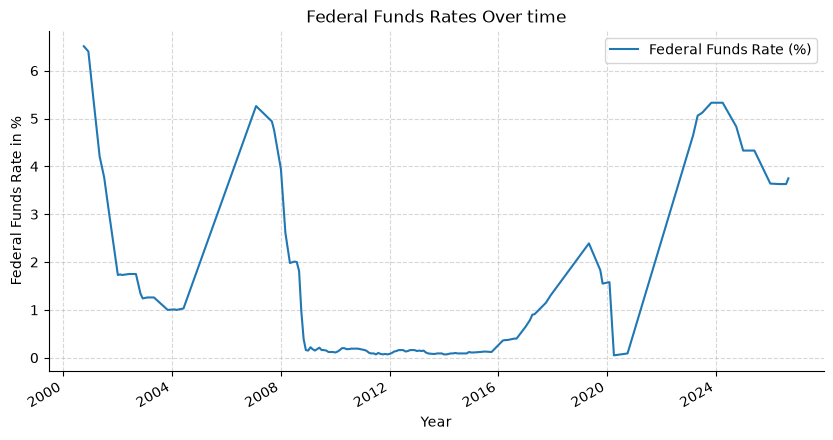

In [25]:
fig, ax= plt.subplots(figsize=(10, 5))

ax.plot(df.index, df['FEDFUNDS'], label='Federal Funds Rate (%)')

ax.legend(loc='upper right')

ax.set_xlabel('Year')
ax.set_ylabel('Federal Funds Rate in %')
ax.set_title('Federal Funds Rates Over time')

ax.grid(True, linestyle='--', alpha=0.5)

fig.autofmt_xdate()

sns.despine()
plt.show()

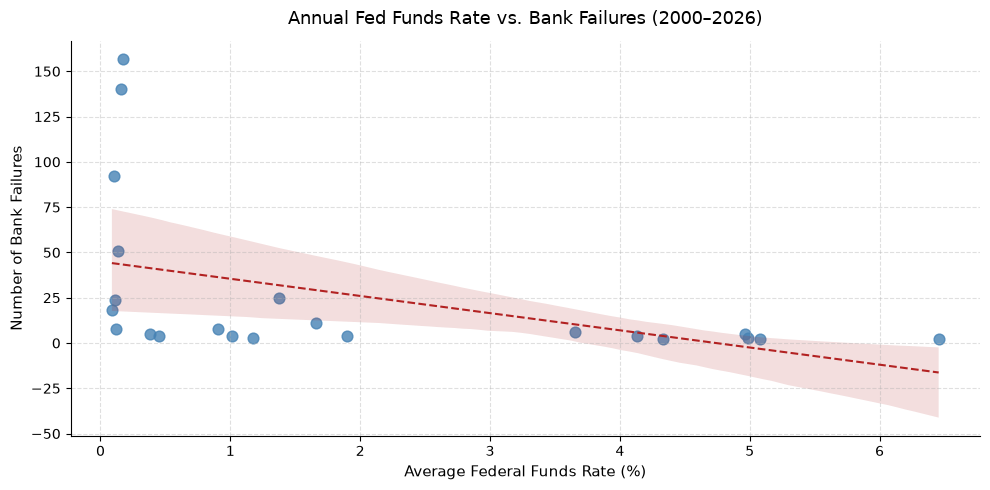

In [26]:
annual_fed = df['FEDFUNDS'].resample('YE').mean()
annual_failures = df['Bank Name'].resample('YE').count()

fig, ax = plt.subplots(figsize=(10, 5))


sns.regplot(
    x=annual_fed, 
    y=annual_failures, 
    ax=ax,
    scatter_kws={'color': 'steelblue', 's': 60, 'alpha': 0.8},
    line_kws={'color': 'firebrick', 'linestyle': '--', 'linewidth': 1.5}
)


ax.set_title('Annual Fed Funds Rate vs. Bank Failures (2000–2026)', fontsize=13, pad=12)
ax.set_xlabel('Average Federal Funds Rate (%)', fontsize=11)
ax.set_ylabel('Number of Bank Failures', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.4)

sns.despine()
plt.tight_layout()
plt.show()

In [27]:
bankrupt_per_state = df['State'].value_counts()
bankrupt_per_state.head()

State
GA    94
FL    76
IL    71
CA    44
MN    23
Name: count, dtype: int64

In [28]:
len(bankrupt_per_state)

44

In [29]:
bankrupt_per_state.index

Index(['GA', 'FL', 'IL', 'CA', 'MN', 'WA', 'AZ', 'MO', 'TX', 'MI', 'KS', 'PA',
       'NV', 'WI', 'MD', 'CO', 'SC', 'OH', 'NJ', 'UT', 'OK', 'TN', 'NC', 'AL',
       'NY', 'OR', 'VA', 'AR', 'LA', 'NE', 'IN', 'PR', 'IA', 'KY', 'NM', 'CT',
       'WV', 'ID', 'MS', 'HI', 'NH', 'WY', 'SD', 'MA'],
      dtype='str', name='State')

In [30]:
df['State'].unique()

<StringArray>
['HI', 'IL', 'NH', 'OH', 'AR', 'TX', 'FL', 'AZ', 'MI', 'CT', 'GA', 'TN', 'LA',
 'CA', 'WI', 'PA', 'NJ', 'NY', 'UT', 'MO', 'MN', 'NV', 'KS', 'WV', 'WA', 'MD',
 'NE', 'OR', 'CO', 'NC', 'ID', 'WY', 'OK', 'SD', 'AL', 'IN', 'IA', 'KY', 'VA',
 'NM', 'PR', 'SC', 'MA', 'MS']
Length: 44, dtype: str

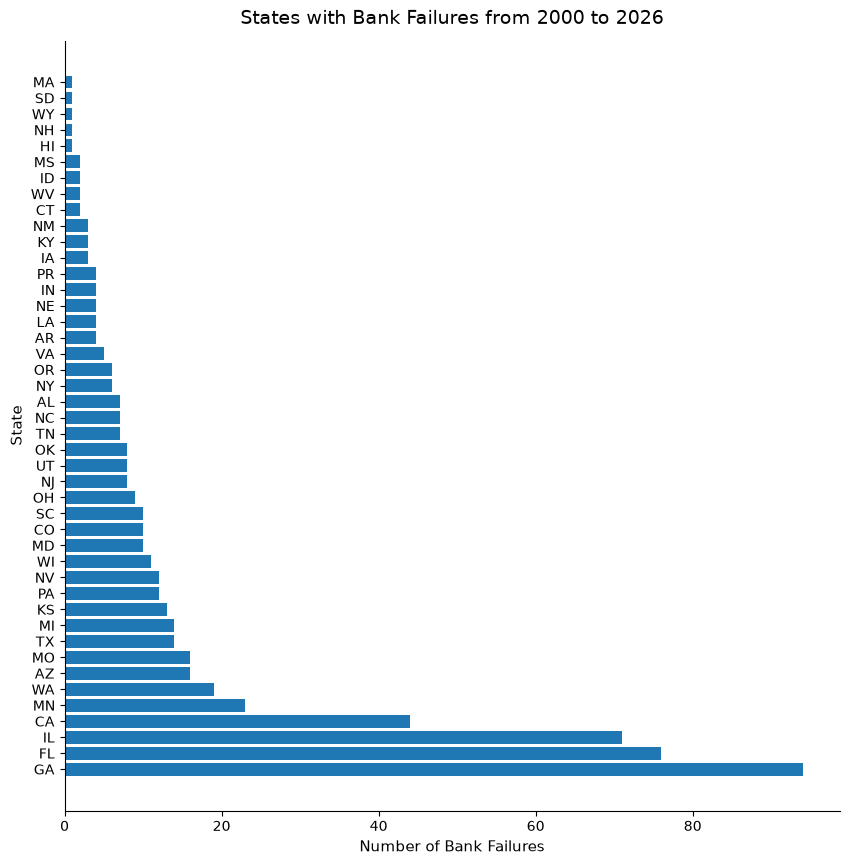

In [31]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.barh(bankrupt_per_state.index, bankrupt_per_state)

ax.set_title('States with Bank Failures from 2000 to 2026', fontsize=14, pad=12)
ax.set_xlabel('Number of Bank Failures', fontsize=11)
ax.set_ylabel('State', fontsize=11)

sns.despine()